# Polity maps
Active individuals per Cliopatria polity, at four century snapshots.

In [1]:
import json
import random
import tempfile

import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from shapely.geometry import shape
from style import *

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DB_PATH = '../data/cultura/humans_clean_enriched_v3.duckdb'
BASEMAP_PATH = '../data/ne_110m_admin_0_countries.geojson'

pl.Config.set_tbl_rows(20)
pl.Config.set_fmt_str_lengths(60)

CENTURY_SNAPSHOTS = [-400, 500, 1400, 1900]

apply_style()

## External data — Natural Earth basemap

In [2]:
basemap = gpd.read_file(BASEMAP_PATH)
print('basemap countries:', len(basemap))

basemap countries: 177


## Load data
### Polity matches

In [3]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")

con.sql("""
    CREATE TEMP TABLE matches AS
    SELECT entity.qid                   AS qid,
           match.polity.cliopatria_id   AS polity_id,
           match.polity.name            AS polity_name,
           peak_productivity.start_year AS peak_start,
           peak_productivity.end_year   AS peak_end
    FROM   individual_enriched, unnest(polity) AS unnested(match)
""")
print('matches:', con.sql('SELECT COUNT(*) FROM matches').fetchone()[0])

matches: 6178833


### Active individuals per polity and century

In [4]:
con.sql("CREATE TEMP TABLE centuries AS SELECT unnest($centuries) AS century",
        params={'centuries': CENTURY_SNAPSHOTS})

century_counts = con.sql("""
    SELECT   centuries.century                              AS century,
             matches.polity_id                            AS polity_id,
             matches.polity_name                          AS polity_name,
             COUNT(*)                               AS n_all
    FROM     matches
    JOIN     centuries ON matches.peak_start <= centuries.century + 99 AND matches.peak_end >= centuries.century
    GROUP BY centuries.century, matches.polity_id, matches.polity_name
""").pl()

assert century_counts.select('century', 'polity_id').is_duplicated().sum() == 0
print('shape:', century_counts.shape)
century_counts.sort('n_all', descending=True).head()

shape: (1926, 4)


century,polity_id,polity_name,n_all
i32,i64,str,i64
1900,1148,"""United States of America""",465417
1900,1389,"""Union of Soviet Socialist Republics""",284950
1900,1412,"""Nazi Germany""",201316
1900,1102,"""Kingdom of Great Britain""",183629
1900,1467,"""French Fifth Republic""",160012


### Polygon per polity and century

In [5]:
con.sql("""
    CREATE TEMP TABLE territories AS
    SELECT cliopatria_id        AS polity_id,
           name                 AS polity_name,
           territory.start_year AS start_year,
           territory.end_year   AS end_year,
           territory.geometry   AS geometry
    FROM   polity, unnest(territories) AS unnested(territory)
""")

polygons = con.sql("""
    SELECT  centuries.century, territories.polity_id, territories.polity_name, territories.start_year, territories.end_year, territories.geometry
    FROM    territories
    JOIN    centuries ON territories.start_year <= centuries.century + 99 AND territories.end_year >= centuries.century
    QUALIFY row_number() OVER (
                PARTITION BY centuries.century, territories.polity_id
                ORDER BY abs((territories.start_year + territories.end_year) / 2.0 - (centuries.century + 50)), territories.start_year
            ) = 1
""").pl()

con.close()

assert polygons.select('century', 'polity_id').is_duplicated().sum() == 0
print('shape:', polygons.shape)
print(polygons.group_by('century').len().sort('century'))
polygons.drop('geometry').head()

shape: (760, 6)
shape: (4, 2)
┌─────────┬─────┐
│ century ┆ len │
│ ---     ┆ --- │
│ i32     ┆ u32 │
╞═════════╪═════╡
│ -400    ┆ 58  │
│ 500     ┆ 112 │
│ 1400    ┆ 240 │
│ 1900    ┆ 350 │
└─────────┴─────┘


century,polity_id,polity_name,start_year,end_year
i32,i64,str,i64,i64
-400,39,"""Greek City-States""",-350,-338
-400,60,"""Xu""",-404,-292
-400,63,"""Hadhramaut""",-700,-351
-400,101,"""Cimmerian Bosporus""",-383,-367
-400,103,"""Han""",-350,-338


## Preprocessing

In [6]:
def century_frame(century, count_column):
    """Polities active in the century, with count and representative geometry."""
    counts = century_counts.filter((pl.col('century') == century) & (pl.col(count_column) > 0))
    joined = counts.join(polygons.filter(pl.col('century') == century).select('polity_id', 'geometry'),
                         on='polity_id', how='inner')
    return gpd.GeoDataFrame({'name': joined['polity_name'].to_list(),
                             'count': joined[count_column].to_list()},
                            geometry=[shape(json.loads(g)).buffer(0) for g in joined['geometry']], crs='EPSG:4326')


def century_label(century):
    return f'{abs(century)} BCE' if century < 0 else f'{century} CE'


def add_log_colorbar(fig, norm, label):
    cbar_ax = fig.add_axes([0.30, 0.05, 0.42, 0.016])
    mappable = ScalarMappable(norm=norm, cmap=MAP_COLORMAP)
    cbar = fig.colorbar(mappable, cax=cbar_ax, orientation='horizontal')
    ticks = list(range(int(np.floor(norm.vmax)) + 1))
    cbar.set_ticks(ticks)
    cbar.set_ticklabels([f'{10 ** t:,}' for t in ticks])
    cbar.set_label(label)


def render_century_maps(frames, colorbar_label):
    norm = Normalize(vmin=0, vmax=max(np.log10(f['count'].max() + 1) for f in frames.values()))
    fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
    for ax, (century, frame) in zip(axes.flatten(), frames.items()):
        basemap.boundary.plot(ax=ax, color=BASEMAP_COLOR, linewidth=0.5, zorder=1)
        frame.assign(log_count=np.log10(frame['count'] + 1)).plot(
            ax=ax, column='log_count', cmap=MAP_COLORMAP, norm=norm, edgecolor=BACKGROUND_COLOR, linewidth=0.25, zorder=2)
        ax.set_xlim(-180, 180); ax.set_ylim(-60, 85)
        ax.set_axis_off()
        ax.text(0.02, 0.97, century_label(century), transform=ax.transAxes, fontsize=MAP_PANEL_LABEL_FONTSIZE, va='top')
    fig.subplots_adjust(left=0.01, right=0.99, top=0.99, bottom=0.10, wspace=0.02, hspace=0.05)
    add_log_colorbar(fig, norm, colorbar_label)
    plt.show()

## Figures
### Active individuals per polity

#### Data plotted

In [7]:
century_frames = {c: century_frame(c, 'n_all') for c in CENTURY_SNAPSHOTS}
century_map_data = pl.concat([
    pl.DataFrame({'century': century, 'name': frame['name'].to_list(), 'count': frame['count'].to_list(),
                  'geometry': frame.geometry.to_wkt().to_list()})
    for century, frame in century_frames.items()
])
print('shape:', century_map_data.shape)
century_map_data

shape: (646, 4)


century,name,count,geometry
i32,str,i64,str
-400,"""Peloponnesian League""",382,"""MULTIPOLYGON (((23.056013 36.674877, 22.832832 36.868176, 22…"
-400,"""Maurya Empire""",15,"""MULTIPOLYGON (((80.841652 30.436434, 81.148216 30.115082, 81…"
-400,"""Sabaeans""",4,"""MULTIPOLYGON (((45.36557 15.971843, 45.579044 15.843266, 46.…"
-400,"""Thebans""",27,"""POLYGON ((23.144678 38.286919, 22.980764 38.157841, 22.98806…"
-400,"""Polyperchon""",18,"""POLYGON ((21.915371 40.161167, 21.825277 39.96703, 21.272625…"
-400,"""Etruscans""",35,"""MULTIPOLYGON (((12.373166 42.23621, 12.452373 42.171238, 12.…"
-400,"""Laomedon""",5,"""MULTIPOLYGON (((38.950703 35.000969, 39.167549 34.872288, 39…"
-400,"""Han""",9,"""POLYGON ((112.938637 35.451431, 112.319923 35.451431, 112.26…"
-400,"""Scythia""",1,"""MULTIPOLYGON (((37.543359 47.074561, 36.794824 46.714404, 35…"


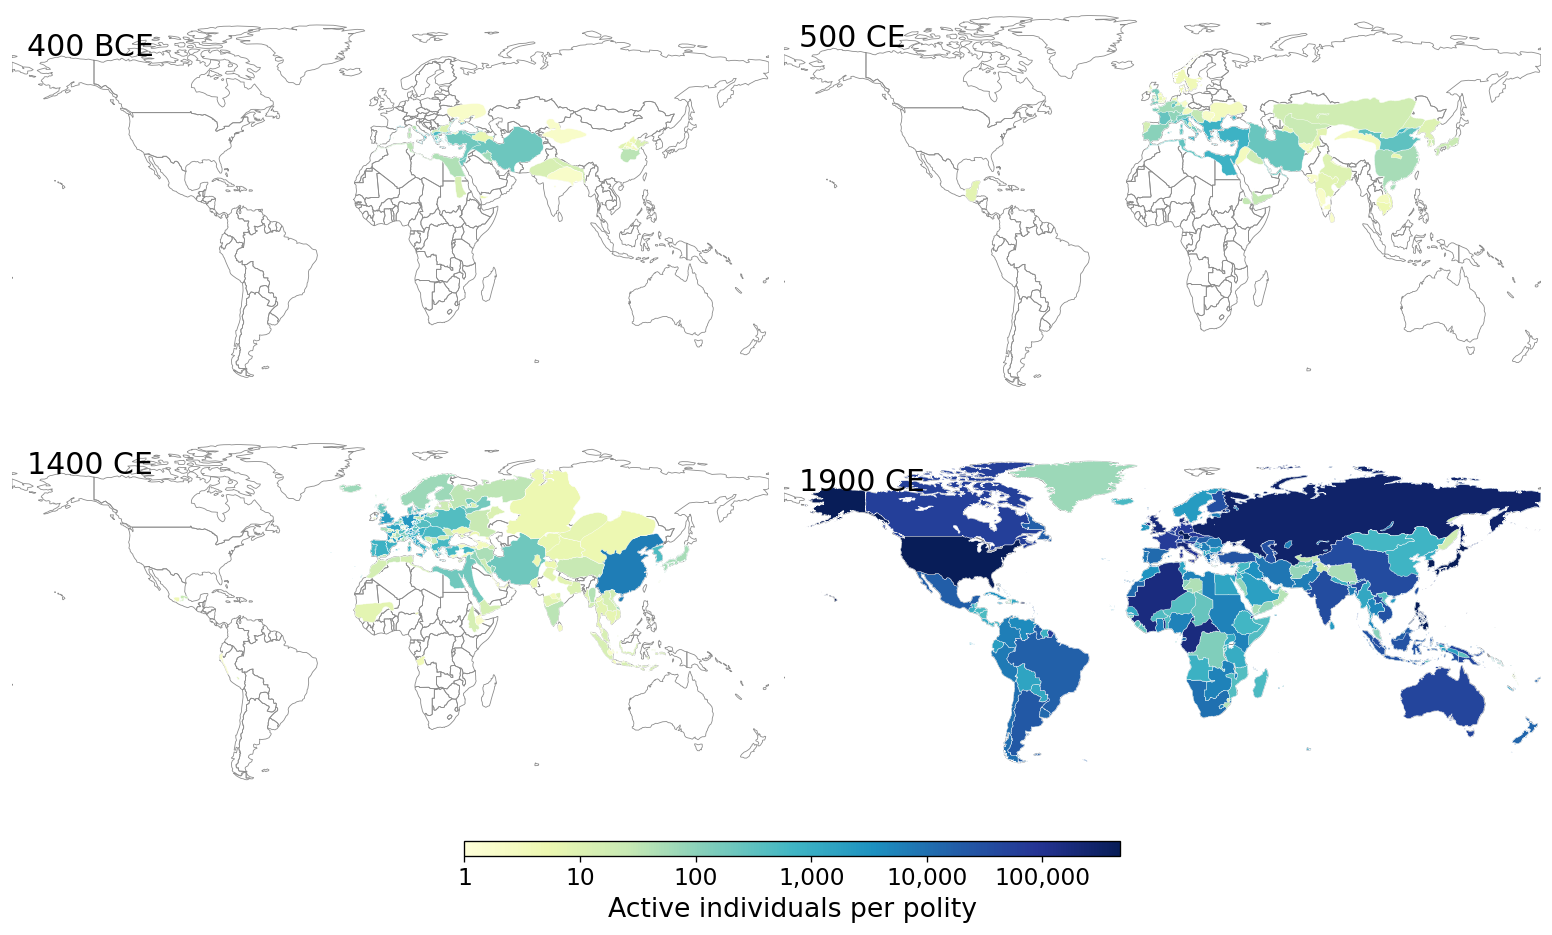

In [8]:
render_century_maps(century_frames, 'Active individuals per polity')